# Lab 8

Author: Khanh Do

In [2]:
import lime
import shap

/home/khanhdo05/jupyter-env/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
## Standard Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn
import warnings   # Turns off the future warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
import xgboost as xgb

In [4]:
## Read the data
ames = pd.read_csv("https://remiller1450.github.io/data/AmesHousing.csv")

## Separate y and X, and keep only a few of the more interesting features to make things manageable
ames_y = ames['SalePrice']
ames_X = ames.drop('SalePrice', axis=1)[['Overall.Qual', 'Overall.Cond', 'Lot.Area', 'Year.Built', 'Total.Bsmt.SF',
                                         'Full.Bath', 'Half.Bath', 'Bedroom.AbvGr', 'Fireplaces', 'Gr.Liv.Area',
                                        'Garage.Area', 'Wood.Deck.SF']]

## Train-test split
from sklearn.model_selection import train_test_split
train_X, test_X, train_y, test_y = train_test_split(ames_X, ames_y, test_size=0.2, random_state=7)

## Create a separate validation set to save the test set for later
train_X, val_X, train_y, val_y = train_test_split(train_X, train_y, test_size=0.25, random_state=7)

## Question 1

### Part A

#### 1. Explore the data

In [5]:
ames_X.head()

,Overall.Qual,Overall.Cond,Lot.Area,Year.Built,Total.Bsmt.SF,Full.Bath,Half.Bath,Bedroom.AbvGr,Fireplaces,Gr.Liv.Area,Garage.Area,Wood.Deck.SF
0,6,5,31770,1960,1080.0,1,0,3,2,1656,528.0,210
1,5,6,11622,1961,882.0,1,0,2,0,896,730.0,140
2,6,6,14267,1958,1329.0,1,1,3,0,1329,312.0,393
3,7,5,11160,1968,2110.0,2,1,3,2,2110,522.0,0
4,5,5,13830,1997,928.0,2,1,3,1,1629,482.0,212


In [6]:
ames_X.shape

(2930, 12)

In [7]:
ames.shape

(2930, 82)

In [8]:
# Verify types of each column as expected
ames_X.dtypes

Overall.Qual       int64
Overall.Cond       int64
Lot.Area           int64
Year.Built         int64
Total.Bsmt.SF    float64
Full.Bath          int64
Half.Bath          int64
Bedroom.AbvGr      int64
Fireplaces         int64
Gr.Liv.Area        int64
Garage.Area      float64
Wood.Deck.SF       int64
dtype: object

In [9]:
# Explore missing values
ames_X.loc[ames_X.isna().any(axis=1)]

,Overall.Qual,Overall.Cond,Lot.Area,Year.Built,Total.Bsmt.SF,Full.Bath,Half.Bath,Bedroom.AbvGr,Fireplaces,Gr.Liv.Area,Garage.Area,Wood.Deck.SF
1341,4,7,5940,1946,NaN,1,0,2,0,896,280.0,0
2236,5,6,9060,1923,859.0,2,0,3,0,1828,NaN,174


NaN is fine because `xgboost` will treat that as unknown.

#### 2. Tune tree with randomized search

In [10]:
from sklearn.model_selection import RandomizedSearchCV

## Simple xgboost model
model = xgb.XGBRegressor(
    eval_metric="rmse",
    random_state=7,
    n_jobs=1
)

## Randomized search space
params = {
    "max_depth": [2, 3, 4, 5, 6],
    "min_child_weight": [1, 5, 10, 20],
    "subsample": [0.50, 0.75, 1.00],
    "colsample_bytree": [0.50, 0.75, 1.00]
}

## Randomized search
rand_res = RandomizedSearchCV(
    model,
    param_distributions=params,
    n_iter=30,
    scoring="neg_root_mean_squared_error",
    cv=5,
    n_jobs=-1,
    random_state=7
).fit(train_X, train_y)

print(rand_res.best_estimator_)
print(rand_res.best_score_)
print(rand_res.best_params_)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=1.0, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric='rmse', feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=None, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=5,
             max_leaves=None, min_child_weight=5, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=None,
             n_jobs=1, num_parallel_tree=None, ...)
-27990.66328125
{'subsample': 1.0, 'min_child_weight': 5, 'max_depth': 5, 'colsample_bytree': 1.0}


In [11]:
params_to_print = [
    'param_max_depth',
    'param_min_child_weight',
    'param_subsample',
    'param_colsample_bytree',
    'mean_test_score'
]
# Display from worst to best
pd.DataFrame(rand_res.cv_results_).sort_values(by='mean_test_score', ascending=True)[params_to_print]

,param_max_depth,param_min_child_weight,param_subsample,param_colsample_bytree,mean_test_score
15,6,5,0.50,0.75,-31911.039453
23,5,1,0.50,0.75,-31808.669531
8,2,1,0.50,1.00,-30858.185547
9,4,1,0.75,1.00,-30815.014453
6,5,10,0.50,0.75,-30745.176172
29,3,1,1.00,1.00,-30744.934375
4,2,10,0.50,1.00,-30624.242578
16,6,1,0.75,0.75,-30549.774609
26,4,1,1.00,0.75,-30509.879297
28,4,20,1.00,1.00,-30455.588281


Seems like we can only omit `param_subsample = 0.50` and `max_depth = 2`.

In [12]:
## Simple xgboost model
model = xgb.XGBRegressor(
    eval_metric="rmse",
    random_state=7,
    n_jobs=1
)

## Expanded randomized search space
params = {
    "max_depth": [3, 4, 5, 6],
    "min_child_weight": [1, 5, 10, 20],
    "subsample": [0.75, 1.00],
    "colsample_bytree": [0.50, 0.75, 1.00],
    "reg_alpha": [0, 1, 10],
    "reg_lambda": [0, 1, 10]
}

## Randomized search
rand_res = RandomizedSearchCV(
    model,
    param_distributions=params,
    n_iter=30,
    scoring="neg_root_mean_squared_error",
    cv=5,
    n_jobs=-1,
    random_state=7
).fit(train_X, train_y)

print(rand_res.best_estimator_)
print(rand_res.best_score_)
print(rand_res.best_params_)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.5, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric='rmse', feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=None, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=4,
             max_leaves=None, min_child_weight=5, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=None,
             n_jobs=1, num_parallel_tree=None, ...)
-28202.284375
{'subsample': 1.0, 'reg_lambda': 0, 'reg_alpha': 1, 'min_child_weight': 5, 'max_depth': 4, 'colsample_bytree': 0.5}


#### 3. Tune learning rate with early stopping

In [13]:
learning_rates = [0.005, 0.01, 0.1, 0.3]
base_model = rand_res.best_estimator_
saved_results = []
saved_models = []

from sklearn.base import clone
for learning_rate in learning_rates:
    curr_model = clone(base_model)
    curr_model.set_params(early_stopping_rounds=80, learning_rate=learning_rate, n_estimators=5000, eval_metric="rmse")
    curr_model.fit(train_X, train_y, eval_set=[(train_X, train_y),(val_X, val_y)],verbose=False)
    print(f"learning rate = {learning_rate}")
    print("best iter =", curr_model.best_iteration)
    print("best validation RMSE =", curr_model.evals_result()["validation_1"]["rmse"][curr_model.best_iteration])
    print("--------")
    saved_models.append(curr_model)
    history = curr_model.evals_result()
    saved_results.append((
        history["validation_0"]["rmse"],
        history["validation_1"]["rmse"]
    ))

learning rate = 0.005
best iter = 1832
best validation RMSE = 25329.807589971744
--------
learning rate = 0.01
best iter = 1017
best validation RMSE = 25086.620263707227
--------
learning rate = 0.1
best iter = 143
best validation RMSE = 25853.653456430842
--------
learning rate = 0.3
best iter = 116
best validation RMSE = 27560.779791138106
--------


#### 4. Report the best estimator and its cross-validated performance.

In [14]:
# best model is the one with the smallest RMSE
best_model = min(saved_models, key=lambda model: model.best_score)

print("Best xgboost model:")
print("learning rate =", best_model.learning_rate)
print("best iter =", best_model.best_iteration)
print("best params =", rand_res.best_params_)
print("best validation RMSE =", best_model.best_score)

Best xgboost model:
learning rate = 0.01
best iter = 1017
best params = {'subsample': 1.0, 'reg_lambda': 0, 'reg_alpha': 1, 'min_child_weight': 5, 'max_depth': 4, 'colsample_bytree': 0.5}
best validation RMSE = 25086.620263707227


### Part B

In [15]:
# Find the cross-validated performance of the random forest model used in this sections examples
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score
rf_score = -cross_val_score(
    RandomForestRegressor(n_estimators=500, max_depth=6, random_state=7),
    train_X,
    train_y,
    scoring="neg_root_mean_squared_error",
    cv=5
).mean()
print("random forest best validation RMSE:", rf_score)

random forest best validation RMSE: 31629.64790978161


The RMSE of the random forest model is higher than that of the xgboost model (31629 vs. 25086).

### Part C

In [16]:
## Permutation importance
from sklearn.inspection import permutation_importance
xgb_imp = permutation_importance(best_model, val_X, val_y, n_repeats=20, scoring="neg_root_mean_squared_error", random_state=7)

## Assemble and print results
imp_results = pd.DataFrame({"Feature": val_X.columns,
                       "Importance": xgb_imp.importances_mean,
                       "Std": xgb_imp.importances_std})
imp_results.sort_values("Importance", ascending=False)

,Feature,Importance,Std
0,Overall.Qual,16685.147656,1043.390828
9,Gr.Liv.Area,10518.838867,824.396382
3,Year.Built,9145.372656,953.382660
4,Total.Bsmt.SF,6533.564551,648.334290
2,Lot.Area,2455.898047,373.774943
1,Overall.Cond,2080.515430,244.449040
10,Garage.Area,1817.320605,516.153119
8,Fireplaces,1526.693262,302.191959
7,Bedroom.AbvGr,968.550000,411.372654
5,Full.Bath,833.725879,146.018705


The two models agree on the top 2 most important features, which are `Overall.Qual` and `Gr.Liv.Area` in that order, and the bottom 2 most important features, which are `Wood.Deck.SF` and `Half.Bath`. However, the xgboost model rank `Wood.Deck.SF` higher than `Half.Bath`, whereas the random forest ranked `Half.Bath` higher. The random forest model also got a much larger importance score for `Overall.Qual` than that of the xgboost model (32612 vs. 16685). The range of importance score is larger for the random forest model.

### Part D

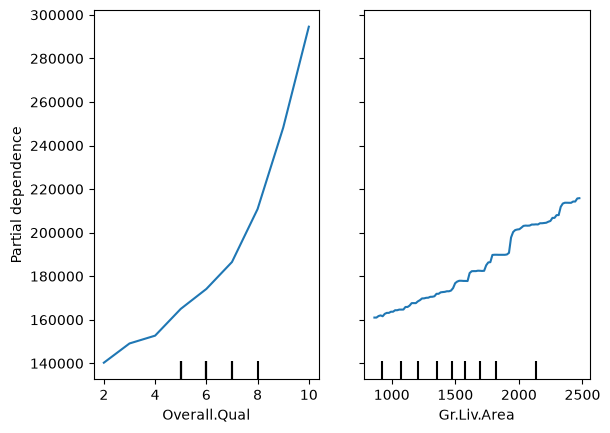

In [17]:
from sklearn.inspection import PartialDependenceDisplay
PartialDependenceDisplay.from_estimator(best_model, val_X.astype(float), features=["Overall.Qual", "Gr.Liv.Area"])
plt.show()

The shapes of these plots are pretty similar to that of the random forest, where both are positive linear, slope and range is similar. The fact that the `Overall.Qual` max partial dependence for the random forest model is higher than that of the xgboost model (350000 vs. 300000) is consistent with the permutation importance table, which is saying that the random forest model places more importance on `Overall.Qual` than the xgboost model.

### Part E

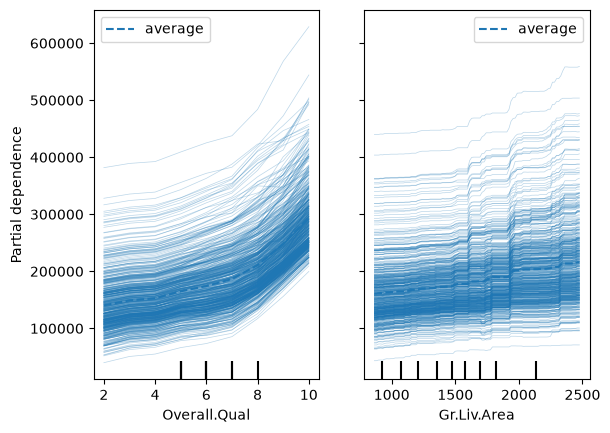

In [18]:
PartialDependenceDisplay.from_estimator(best_model, val_X.astype(float),features=["Overall.Qual", "Gr.Liv.Area"], kind="both")
plt.show()

`Overall.Qual` seems to show more heterogeneity because there are more crossing lines. The amount of heterogeneity for the random forest's `Overall.Qual` is more than the above one by xgboost.

## Question 2

### Part A

Predicted price = $123211.6640625


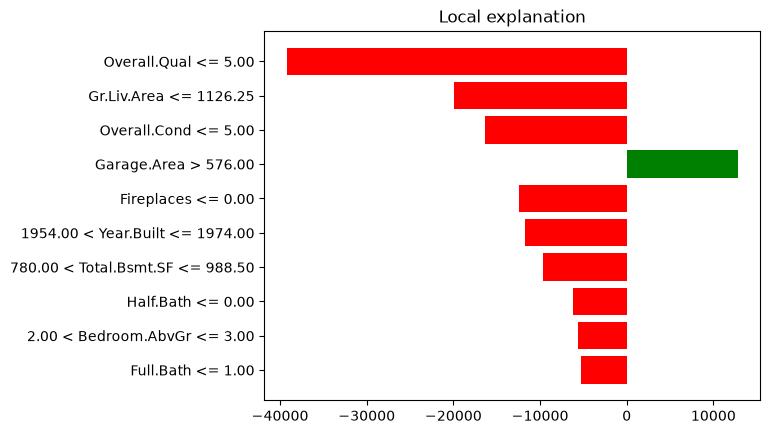

In [36]:
# Create a LIME explanation plot for the 5th observation in the validation set.
from lime.lime_tabular import LimeTabularExplainer
warnings.filterwarnings("ignore", message="X does not have valid feature names")

## First, fit the explainer
lime_explainer = LimeTabularExplainer(training_data=train_X.values,feature_names=train_X.columns,mode="regression",random_state=15)

## Next, provide the observation whose prediction is to be explained
lime_exp = lime_explainer.explain_instance(val_X.iloc[5-1].values, best_model.predict,num_features=10)

## Print the predicted price
predicted_price = best_model.predict(val_X.iloc[[4]])[0]
print(f"Predicted price = ${predicted_price}")

## Plot the local explanation
lime_exp.as_pyplot_figure()
plt.show()

The model predicts the fifth house with sale price of around $123211. The model pushed the price down for the fact that it is an old, low quality home with smaller living area, lower overall condition, etc. but being rewarded for a larger garage area.

### Part B

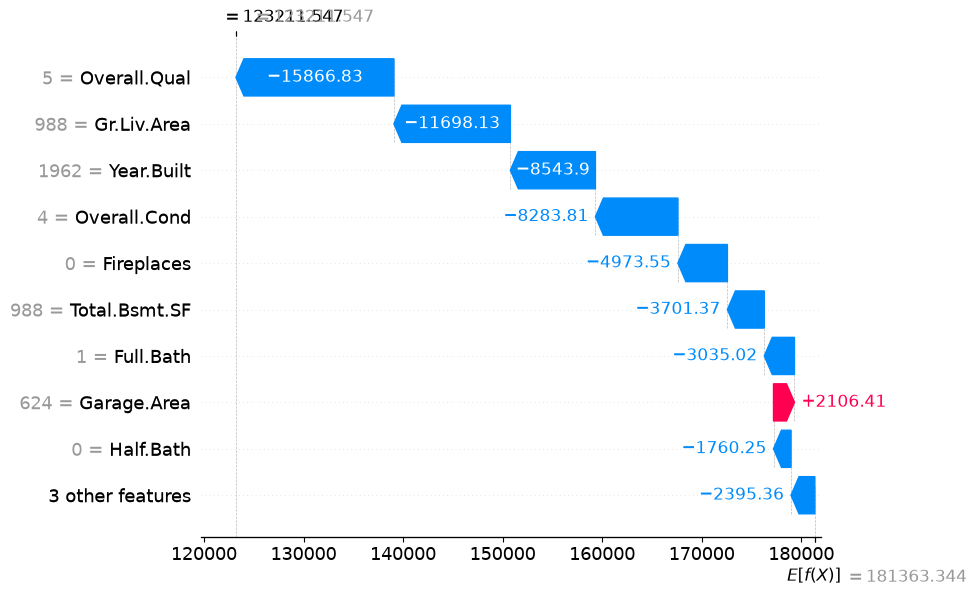

In [26]:
# Create a SHAP waterfall plot for the same home (the 5th observation in the validation set).
## Fit the explainer
shap_explainer = shap.TreeExplainer(best_model)

## Apply the explainer
shap_values = shap_explainer.shap_values(val_X)

## Waterfall Plot - a local explanation of fifth home in the validation set
home1_shap = shap.Explanation(values=shap_values[5-1], base_values= shap_explainer.expected_value, data=val_X.iloc[5-1], feature_names=val_X.columns)
shap.plots.waterfall(home1_shap)

Same story as the LIME plot (the negative influence and the positive influence) but the SHAP plot gives `Year.Built` more importance than LIME does. Also the contribution sizes differ, probably because of each method's mechanism.

### Part C

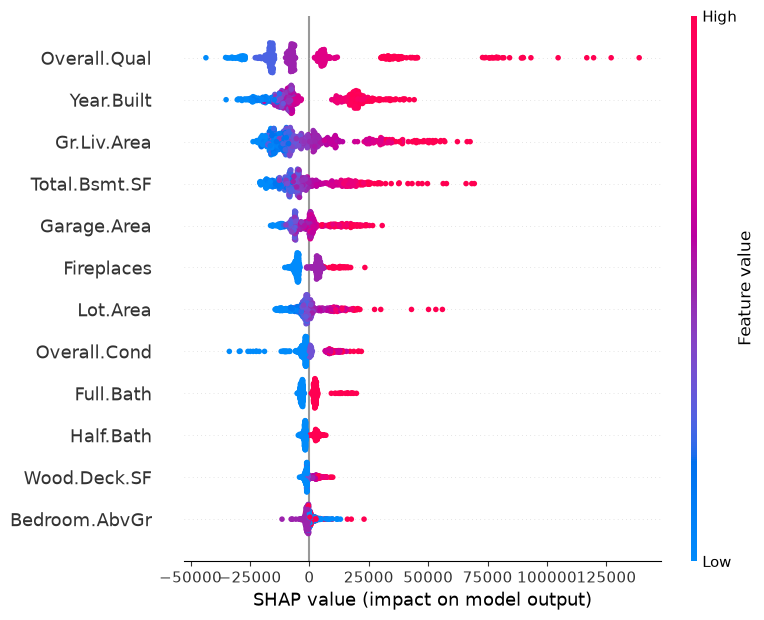

In [28]:
# Create a SHAP beeswarm plot - a global explanation of each feature's role in the model
shap.summary_plot(shap_values, val_X)

- i. The most important if `Overall.Qual` and the least important is `Bedroom.AbvGr`
- ii. A feature that might not have a monotonic relationship with the outcome in the model is `Bedroom.AbvGr` because of the colors distribution.

### Part D

The rankings generally agree with each other. They both point to `Overall.Qual` as the most important feature, and then `Gr.Liv.Area` and `Year.Built` (but in different orders), then `Total.Bsmt.SF`. However, SHAP ranks `Garage.Area` and `Fireplaces` higher while permutation importance table ranks `Lot.Area` and `Overall.Cond` higher. SHAP identified `Bedroom.AbvGr` is the least important feature, while permutation importance table ranks `Half.Bath` last.

In the case of disagreements, I would prefer SHAP because it also shows me how big the contribution is and the direction (negative or positive) of the ranked features.

### Part E

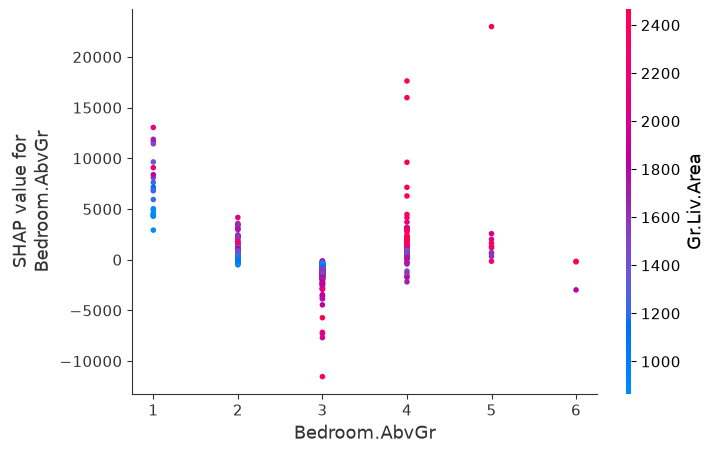

In [39]:
# create a SHAP dependence plot for the feature you identified in Part C - ii
shap.dependence_plot("Bedroom.AbvGr", shap_values, val_X, interaction_index="Gr.Liv.Area")
plt.show()